In [1]:
# import the necessary libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
## import and read the dataset
data=pd.read_csv('credit_card.csv')
data.head()

,actionnr,merchant_id,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq,isfradulent
0,1,3160040998,100.0,3000.0,N,5,Y,Y,0,0.0,0,Y
1,2,3160040998,100.0,4300.0,N,5,Y,Y,0,0.0,0,Y
2,3,3160041896,185.5,4823.0,Y,5,N,N,0,0.0,0,Y
3,4,3160141996,185.5,5008.5,Y,8,N,N,0,0.0,0,Y
4,5,3160241992,500.0,26000.0,N,0,Y,Y,800,677.2,6,Y


In [3]:
## 

In [4]:
type(data)

pandas.core.frame.DataFrame

In [5]:
# Remove the target column from the dataset
data=data.drop(columns=['actionnr','merchant_id','isfradulent'])
data.head()

,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq
0,100.0,3000.0,N,5,Y,Y,0,0.0,0
1,100.0,4300.0,N,5,Y,Y,0,0.0,0
2,185.5,4823.0,Y,5,N,N,0,0.0,0
3,185.5,5008.5,Y,8,N,N,0,0.0,0
4,500.0,26000.0,N,0,Y,Y,800,677.2,6


In [6]:
## Identify the dataframe structure to  evaluvate meta data, assess the data quality, and understand of the dataset composition
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   average_amount_transaction_day  3075 non-null   float64
 1   transaction_amount              3075 non-null   float64
 2   is_declined                     3075 non-null   object 
 3   total_number_of_declines_day    3075 non-null   int64  
 4   isforeigntransaction            3075 non-null   object 
 5   ishighriskcountry               3075 non-null   object 
 6   daily_chargeback_avg_amt        3075 non-null   int64  
 7   sixmonth_avg_chbk_amt           3075 non-null   float64
 8   sixmonth_chbk_freq              3075 non-null   int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 216.3+ KB


In [7]:
## Rename the columns of the dataframe

In [8]:
# Print all column names as a list so you can see them clearly
print(data.columns.tolist())
for  i in data.columns.tolist():
    print(i)

['average_amount_transaction_day', 'transaction_amount', 'is_declined', 'total_number_of_declines_day', 'isforeigntransaction', 'ishighriskcountry', 'daily_chargeback_avg_amt', 'sixmonth_avg_chbk_amt', 'sixmonth_chbk_freq']
average_amount_transaction_day
transaction_amount
is_declined
total_number_of_declines_day
isforeigntransaction
ishighriskcountry
daily_chargeback_avg_amt
sixmonth_avg_chbk_amt
sixmonth_chbk_freq


In [9]:
data = data.rename(columns={"average_amount_transaction_day":"average_amount_transaction_day","transaction_amount":"transaction_amount","is_declined":"is_declined","total_number_of_declines_day":"total_number_of_declines_day","isforeigntransaction": "is_foreign_transaction", "ishighriskcountry": "is_high_risk_country","daily_chargeback_avg_amt":"daily_chargeback_avg_amt", "sixmonth_avg_chbk_amt":"sixmonth_avg_chbk_amt","sixmonth_chbk_freq":"sixmoth_chbk_freq"})
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   average_amount_transaction_day  3075 non-null   float64
 1   transaction_amount              3075 non-null   float64
 2   is_declined                     3075 non-null   object 
 3   total_number_of_declines_day    3075 non-null   int64  
 4   is_foreign_transaction          3075 non-null   object 
 5   is_high_risk_country            3075 non-null   object 
 6   daily_chargeback_avg_amt        3075 non-null   int64  
 7   sixmonth_avg_chbk_amt           3075 non-null   float64
 8   sixmoth_chbk_freq               3075 non-null   int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 216.3+ KB


In [10]:
data.head()

,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,is_foreign_transaction,is_high_risk_country,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmoth_chbk_freq
0,100.0,3000.0,N,5,Y,Y,0,0.0,0
1,100.0,4300.0,N,5,Y,Y,0,0.0,0
2,185.5,4823.0,Y,5,N,N,0,0.0,0
3,185.5,5008.5,Y,8,N,N,0,0.0,0
4,500.0,26000.0,N,0,Y,Y,800,677.2,6


In [11]:
## Converting the categorical attributes into  numerical values

In [12]:
#encoder=OneHotEncoder(sparse_output=False,dtype=int)

In [13]:
#encoded_data=encoder.fit_transform(data[['is_declined','is_foreign_transaction','is_high_risk_country']])
#encoded_data

In [14]:
#encoded_df = pd.DataFrame(
 #   encoded_data,
#)

#print(encoded_df.head())

In [15]:
cols = ['is_declined','is_foreign_transaction','is_high_risk_country']

encoder = OneHotEncoder(
    sparse_output=False,
    drop='if_binary',
    handle_unknown='ignore'
)

encoded_data = encoder.fit_transform(data[cols])
## Get the feature names                                 
feature_names = encoder.get_feature_names_out(cols)
## converting the encoded data  into  pandas dataframe
encoded_df = pd.DataFrame(encoded_data, columns=feature_names, index=data.index)
# Drop the old unencoded columns and join the new named columns
data = data.drop(columns=cols)
data
# Concatenate the  encoded dataframe with original dataframe
data = pd.concat([data, encoded_df], axis=1)
data.head()

#Replace values in the same columns
#data[cols] = encoded_data

#data.head()

,average_amount_transaction_day,transaction_amount,total_number_of_declines_day,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmoth_chbk_freq,is_declined_Y,is_foreign_transaction_Y,is_high_risk_country_Y
0,100.0,3000.0,5,0,0.0,0,0.0,1.0,1.0
1,100.0,4300.0,5,0,0.0,0,0.0,1.0,1.0
2,185.5,4823.0,5,0,0.0,0,1.0,0.0,0.0
3,185.5,5008.5,8,0,0.0,0,1.0,0.0,0.0
4,500.0,26000.0,0,800,677.2,6,0.0,1.0,1.0


In [16]:
## check the correlational coefficient

In [17]:
data.corr()

,average_amount_transaction_day,transaction_amount,total_number_of_declines_day,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmoth_chbk_freq,is_declined_Y,is_foreign_transaction_Y,is_high_risk_country_Y
average_amount_transaction_day,1.000000,0.587111,-0.009682,0.060429,0.060284,0.071849,0.081184,0.047316,0.014604
transaction_amount,0.587111,1.000000,0.259309,0.252298,0.259663,0.297623,0.197009,0.276764,0.325397
total_number_of_declines_day,-0.009682,0.259309,1.000000,0.094834,0.081138,0.085028,0.115961,0.227904,0.292459
daily_chargeback_avg_amt,0.060429,0.252298,0.094834,1.000000,0.953663,0.884611,0.394083,0.054798,0.074902
sixmonth_avg_chbk_amt,0.060284,0.259663,0.081138,0.953663,1.000000,0.851339,0.407917,0.060566,0.073167
sixmoth_chbk_freq,0.071849,0.297623,0.085028,0.884611,0.851339,1.000000,0.499365,0.077083,0.098241
is_declined_Y,0.081184,0.197009,0.115961,0.394083,0.407917,0.499365,1.000000,0.079761,0.127586
is_foreign_transaction_Y,0.047316,0.276764,0.227904,0.054798,0.060566,0.077083,0.079761,1.000000,0.489572
is_high_risk_country_Y,0.014604,0.325397,0.292459,0.074902,0.073167,0.098241,0.127586,0.489572,1.000000


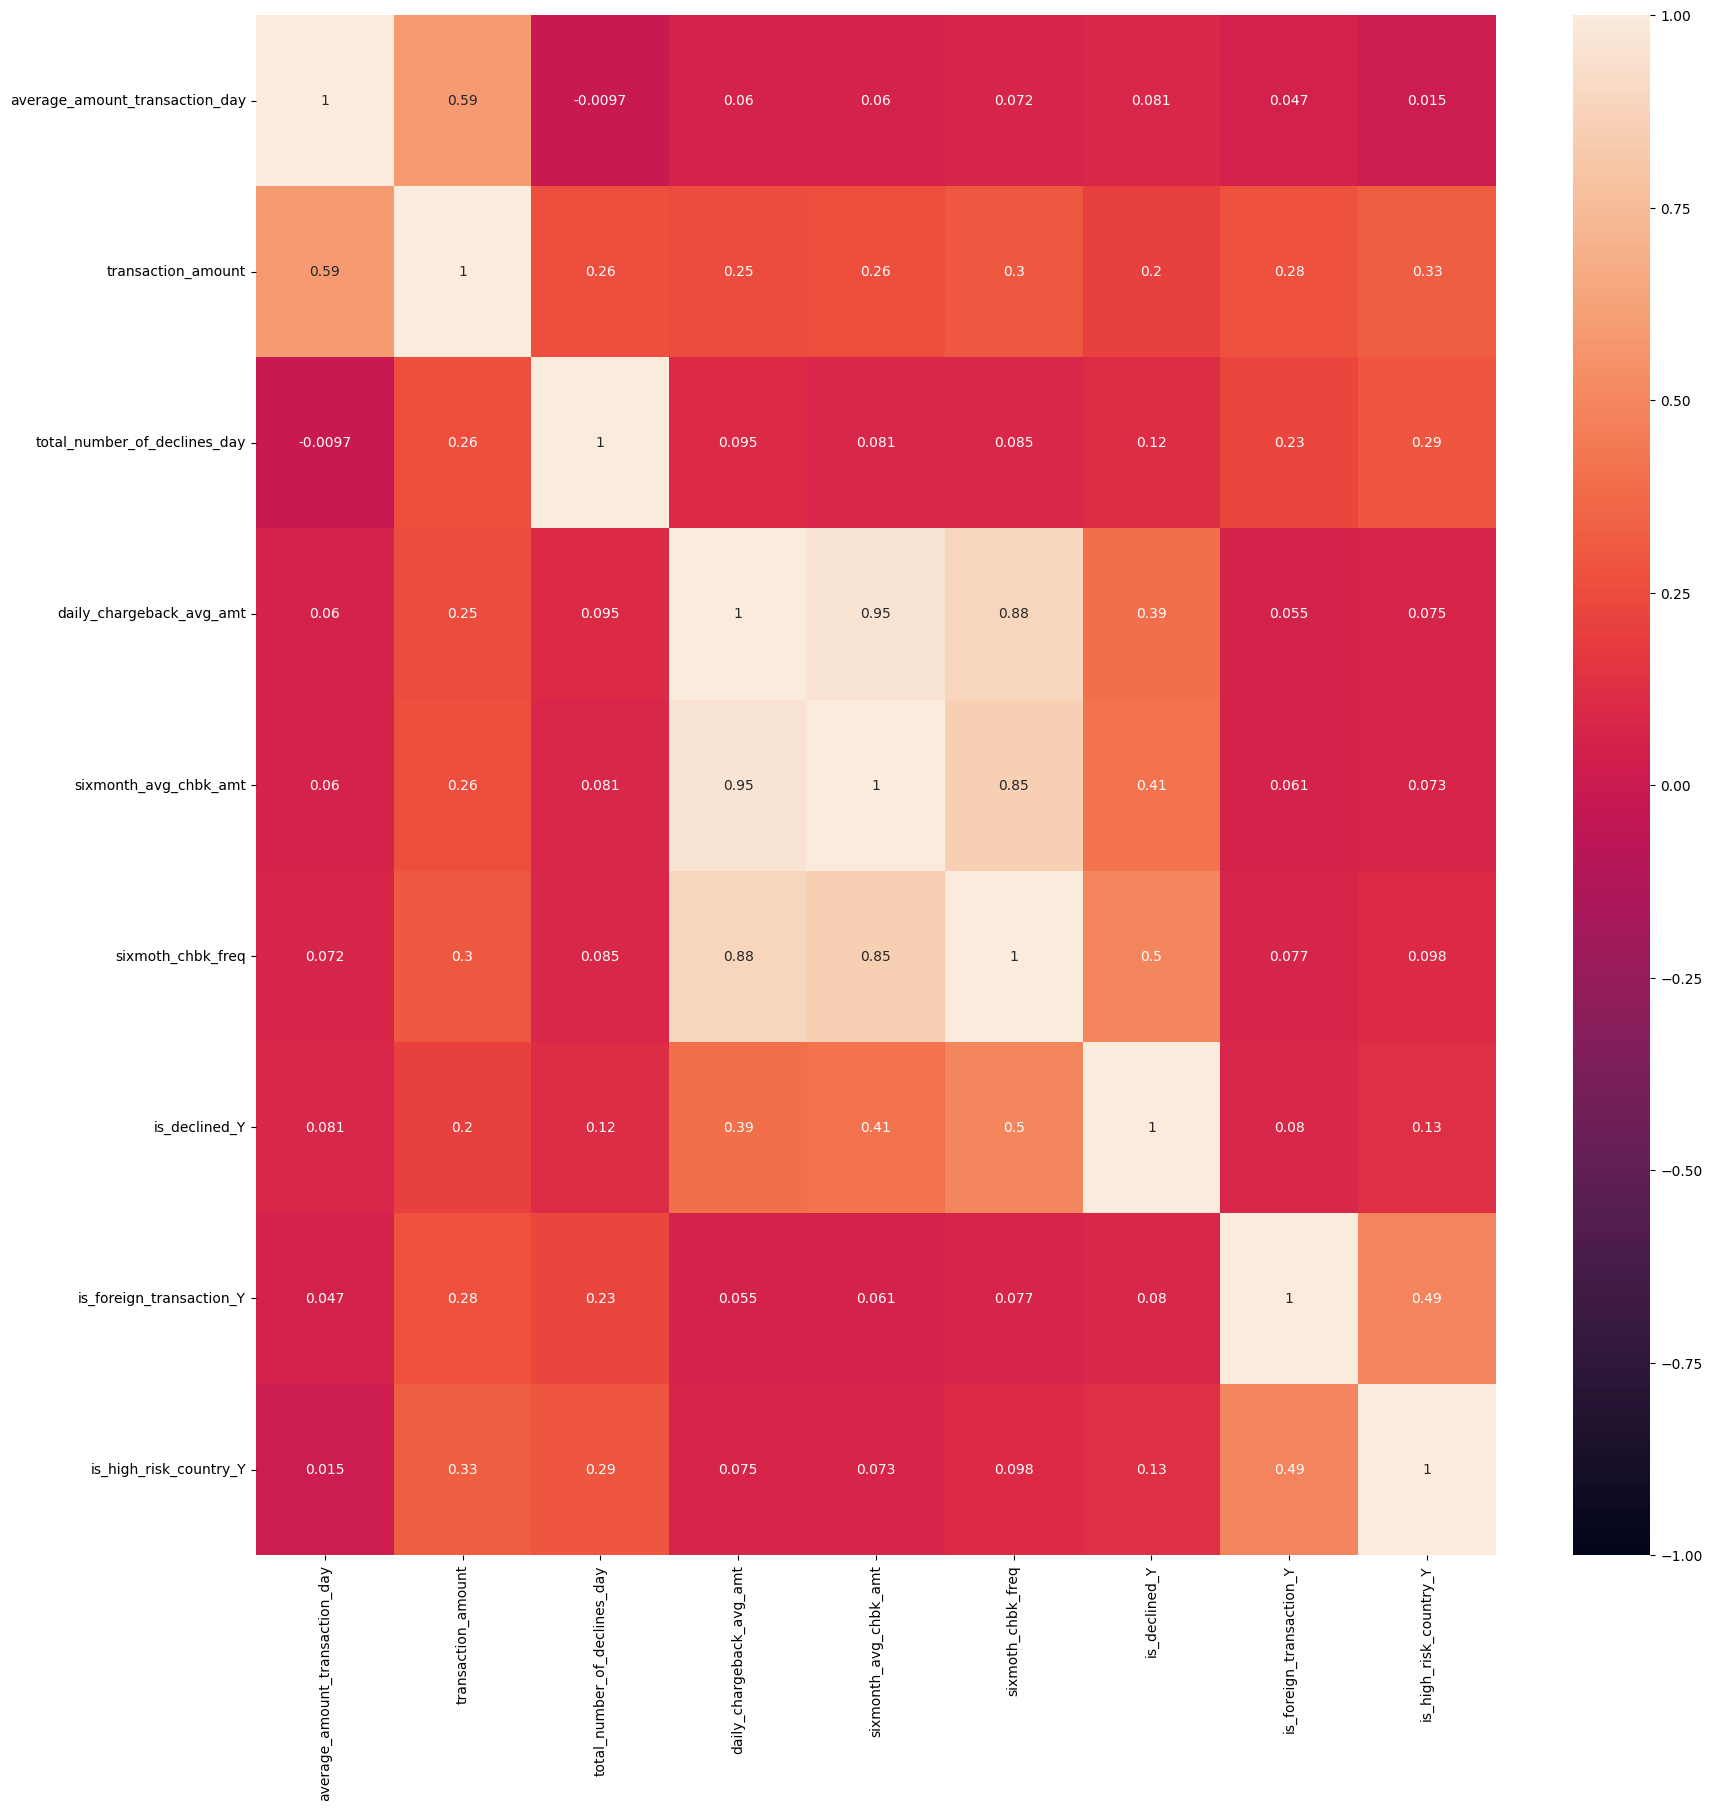

In [18]:
## Graphical represent the  correlational coefficient using heatmap
plt.figure(figsize=(20,20))
sns.heatmap(data.corr(),annot=True,vmin=-1, vmax=1)
plt.show()

#                                              Correlational Coefficiency Spectrum
#### According to the above correlational coefficient matrix and  its graphical representation (heatmap)   mainly  represented  coefficiency between features
#### when it comes to the clustering scenario these variables  cofficiency is important. To measure the coefficient coefficiency
#### we have to use correlational coefficient spectrum. 
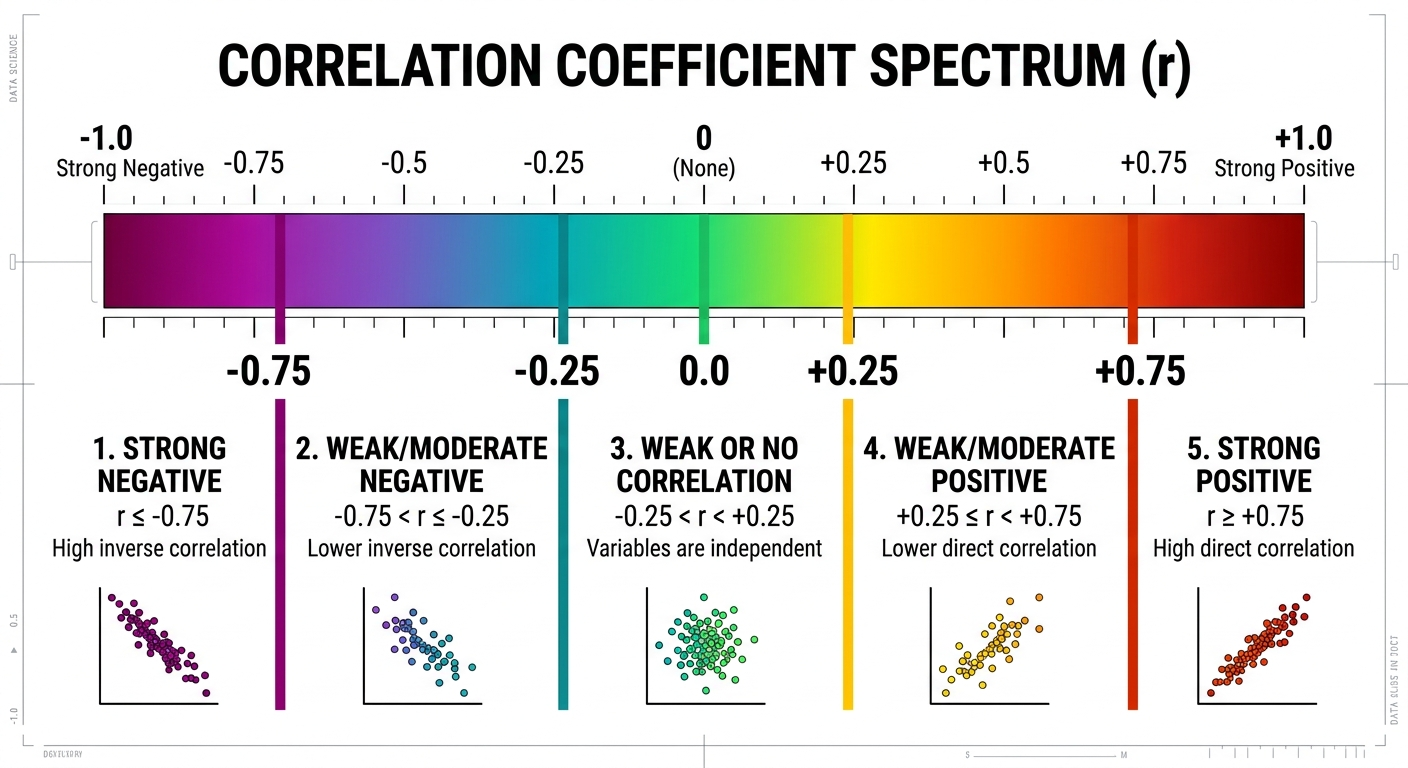

#### According to the above spectrum, we consider  strong correlational, and moderate  correlational features in positive side and negative side

In [19]:
## Represented the all the scatterplots in pairplot

<Figure size 3000x3000 with 0 Axes>

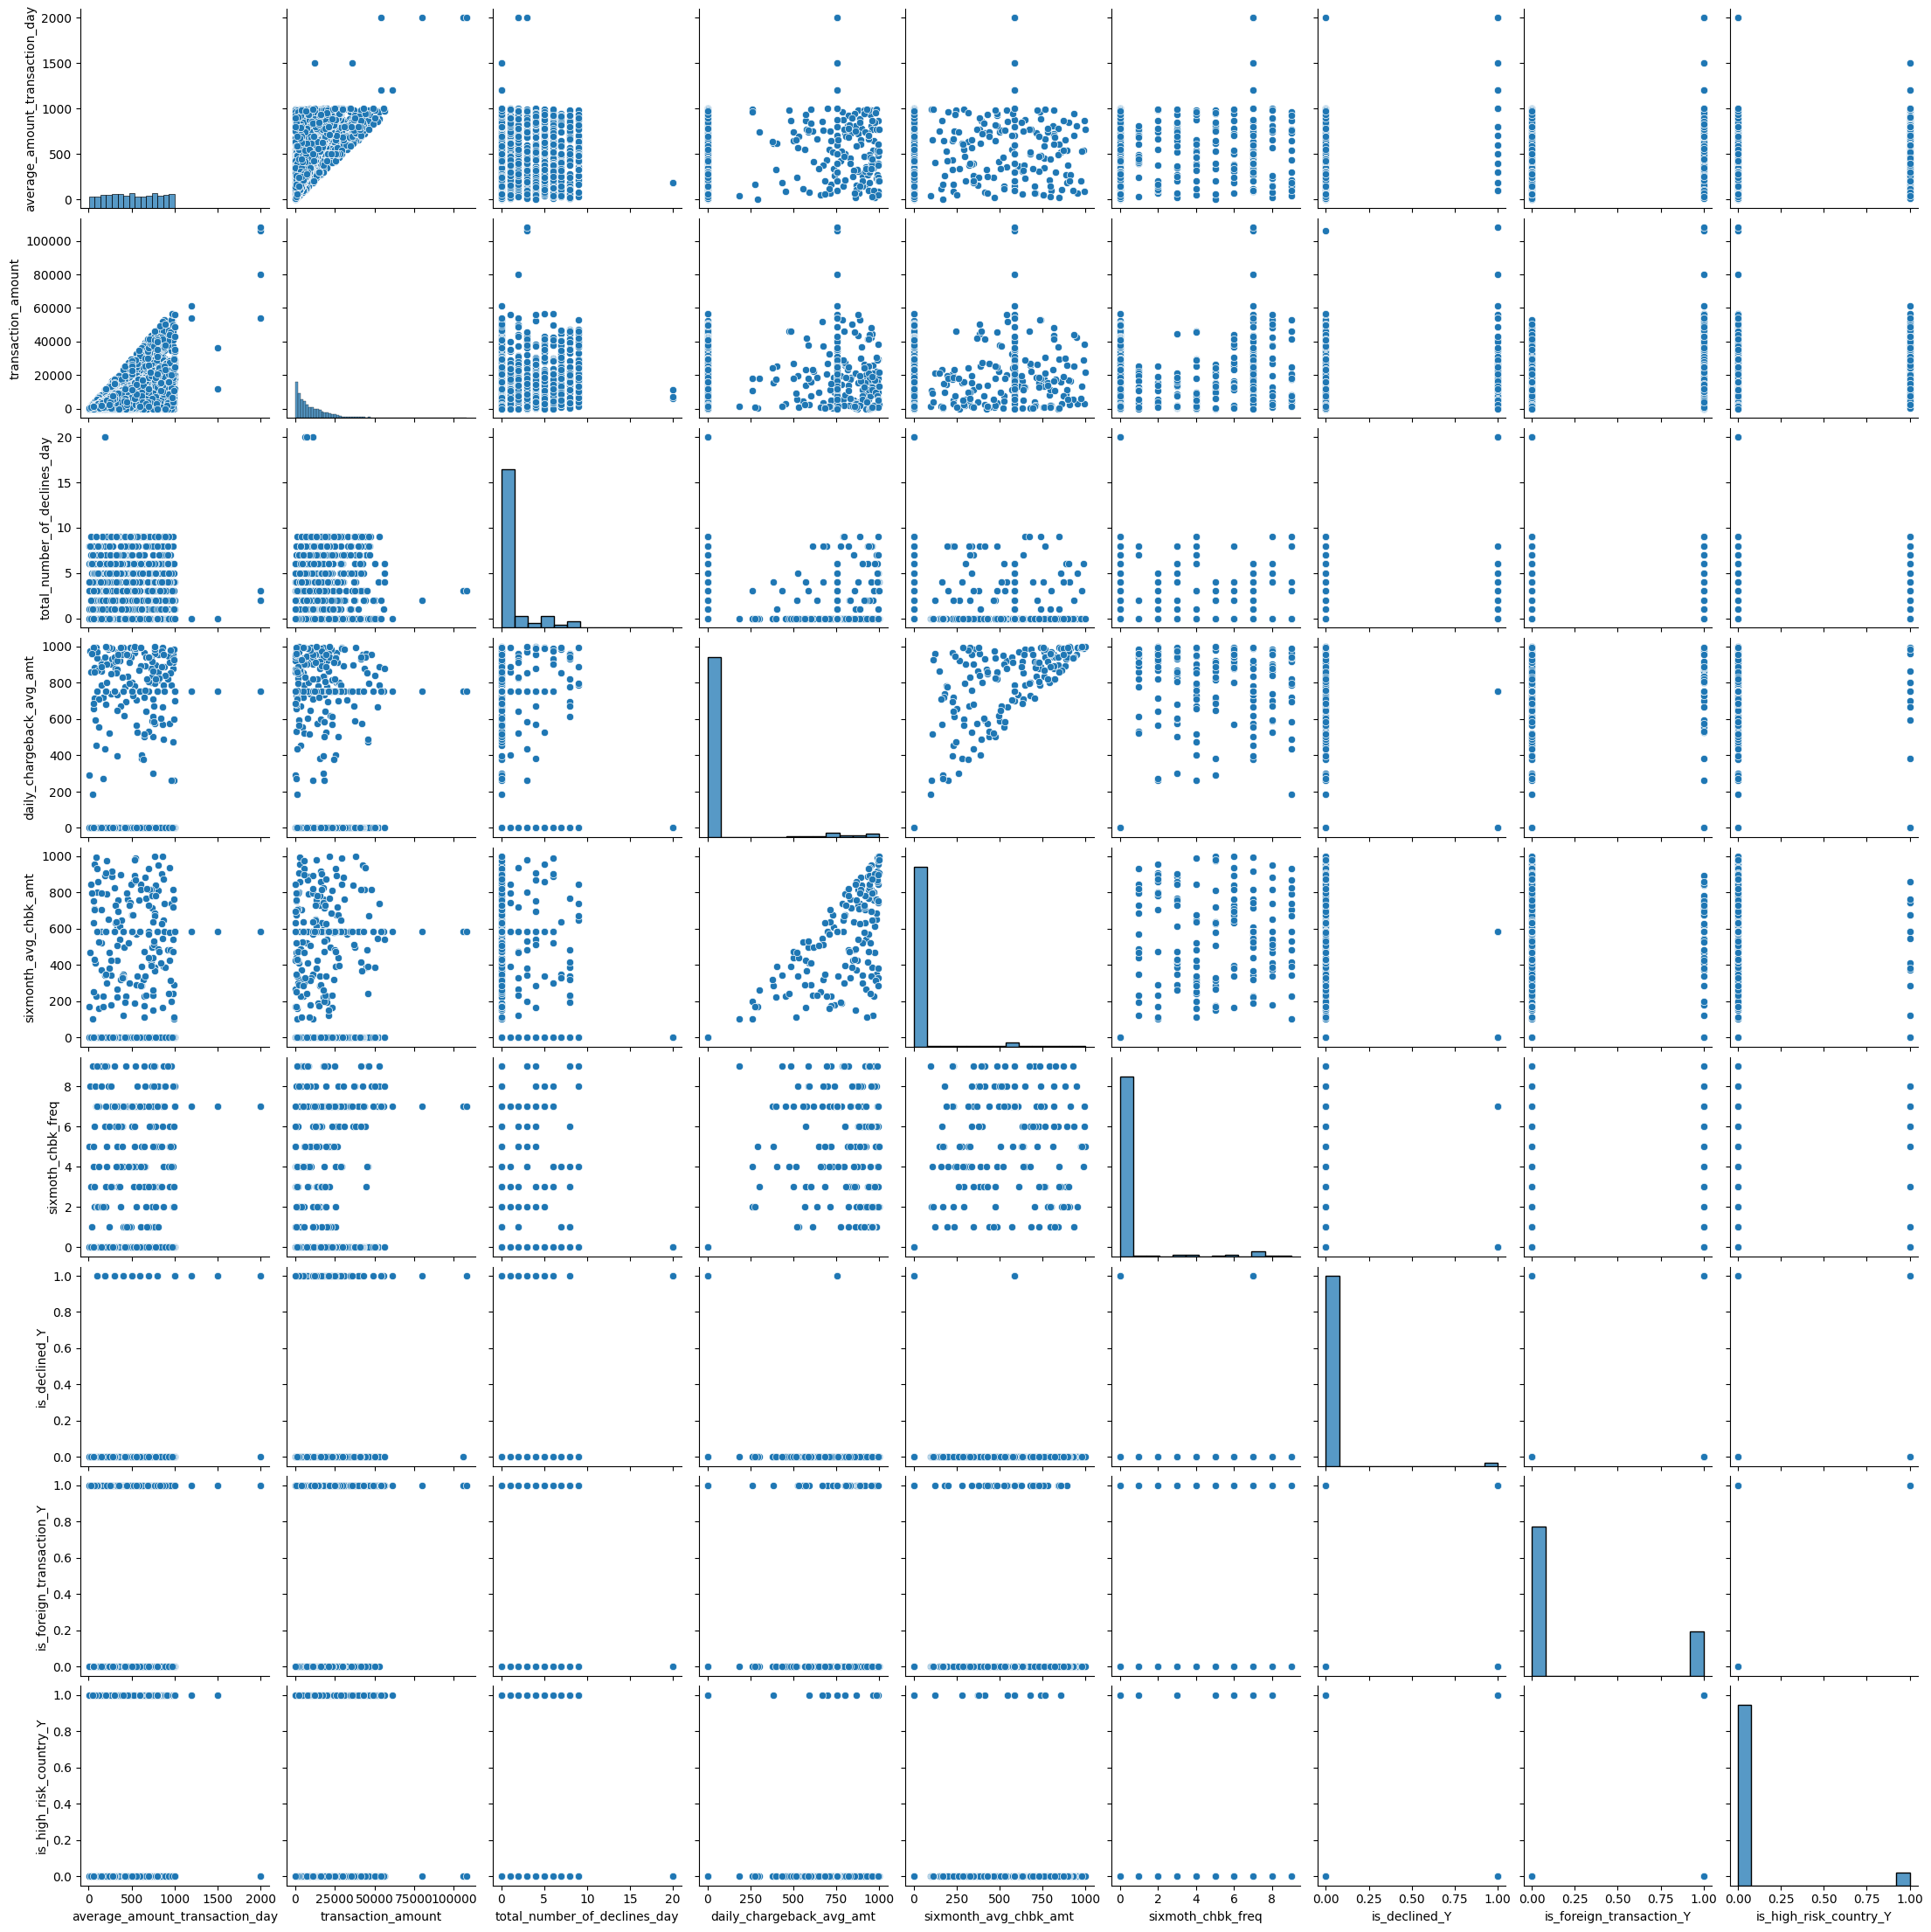

In [20]:
plt.figure(figsize=(30,30))
sns.pairplot(data)
plt.show()

In [21]:
## selected onlythe moderate and  strong  postive and  negative correlational coefficiency related features

In [22]:

corr_matrix = data.corr()

#  Unstack the matrix to list pairs instead of a grid
corr_pairs = corr_matrix.unstack()

# Filter for values >= 0.25, but exclude self-correlations (which are always 1.0)
filtered_pairs = corr_pairs[
    (abs(corr_pairs) >= 0.25) & (abs(corr_pairs) < 1.0)
]
# Sort in descending order (highest to lowest)
sorted_pairs = filtered_pairs.sort_values(ascending=False)

# Print the sorted pairs
print(sorted_pairs)

sixmonth_avg_chbk_amt           daily_chargeback_avg_amt          0.953663
daily_chargeback_avg_amt        sixmonth_avg_chbk_amt             0.953663
sixmoth_chbk_freq               daily_chargeback_avg_amt          0.884611
daily_chargeback_avg_amt        sixmoth_chbk_freq                 0.884611
sixmoth_chbk_freq               sixmonth_avg_chbk_amt             0.851339
sixmonth_avg_chbk_amt           sixmoth_chbk_freq                 0.851339
transaction_amount              average_amount_transaction_day    0.587111
average_amount_transaction_day  transaction_amount                0.587111
is_declined_Y                   sixmoth_chbk_freq                 0.499365
sixmoth_chbk_freq               is_declined_Y                     0.499365
is_high_risk_country_Y          is_foreign_transaction_Y          0.489572
is_foreign_transaction_Y        is_high_risk_country_Y            0.489572
is_declined_Y                   sixmonth_avg_chbk_amt             0.407917
sixmonth_avg_chbk_amt    

In [23]:
sorted_pairs

sixmonth_avg_chbk_amt           daily_chargeback_avg_amt          0.953663
daily_chargeback_avg_amt        sixmonth_avg_chbk_amt             0.953663
sixmoth_chbk_freq               daily_chargeback_avg_amt          0.884611
daily_chargeback_avg_amt        sixmoth_chbk_freq                 0.884611
sixmoth_chbk_freq               sixmonth_avg_chbk_amt             0.851339
sixmonth_avg_chbk_amt           sixmoth_chbk_freq                 0.851339
transaction_amount              average_amount_transaction_day    0.587111
average_amount_transaction_day  transaction_amount                0.587111
is_declined_Y                   sixmoth_chbk_freq                 0.499365
sixmoth_chbk_freq               is_declined_Y                     0.499365
is_high_risk_country_Y          is_foreign_transaction_Y          0.489572
is_foreign_transaction_Y        is_high_risk_country_Y            0.489572
is_declined_Y                   sixmonth_avg_chbk_amt             0.407917
sixmonth_avg_chbk_amt    

In [24]:
data.columns

Index(['average_amount_transaction_day', 'transaction_amount',
       'total_number_of_declines_day', 'daily_chargeback_avg_amt',
       'sixmonth_avg_chbk_amt', 'sixmoth_chbk_freq', 'is_declined_Y',
       'is_foreign_transaction_Y', 'is_high_risk_country_Y'],
      dtype='object')

In [25]:
## Apply the K-means clustering algorithm

In [26]:
kmc=KMeans(n_clusters=2)
kmc

KMeans(n_clusters=2)

In [27]:
kmc.fit_transform(data.iloc[:,1:])

C:\Users\THIS PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\THIS PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\THIS PC\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\THIS PC\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close

array([[ 2259.96023208, 20939.98844622],
       [  960.4462003 , 19640.02682235],
       [  438.45451279, 19117.04373416],
       ...,
       [15567.27776003,  3239.3895895 ],
       [ 6802.14091988, 11966.08701324],
       [30753.99582664, 12087.0022002 ]])

In [28]:
kmc.labels_

array([0, 0, 0, ..., 1, 0, 1])

Data shape: (3075, 9)
Cluster centers shape: (2, 8)


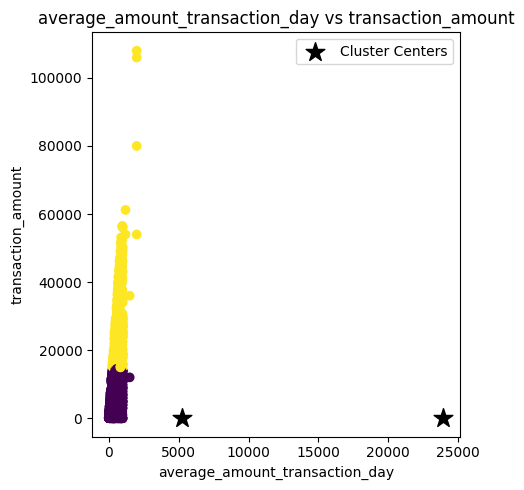

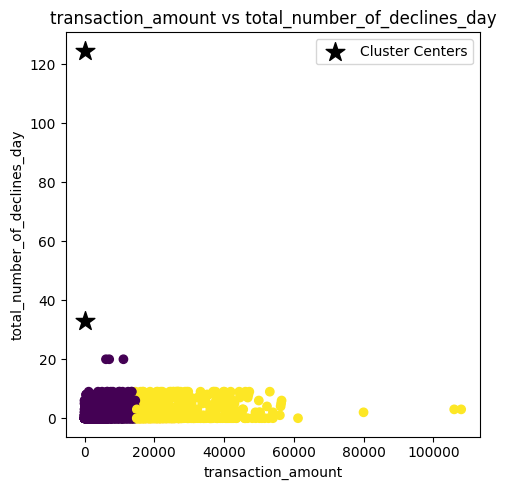

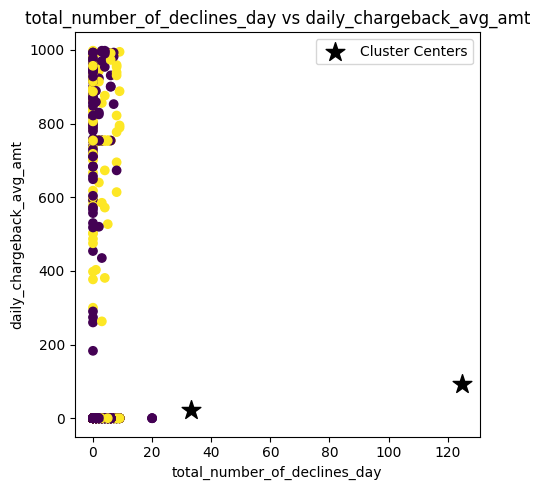

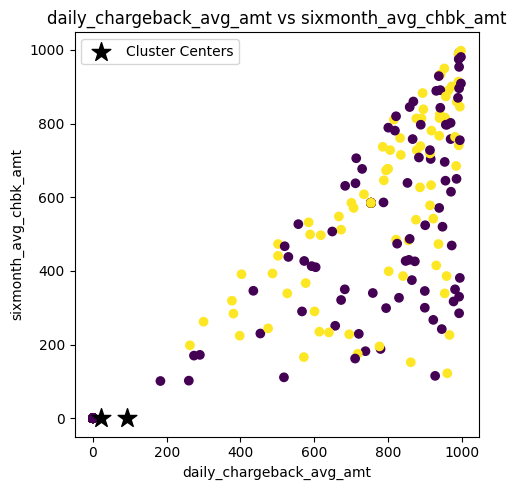

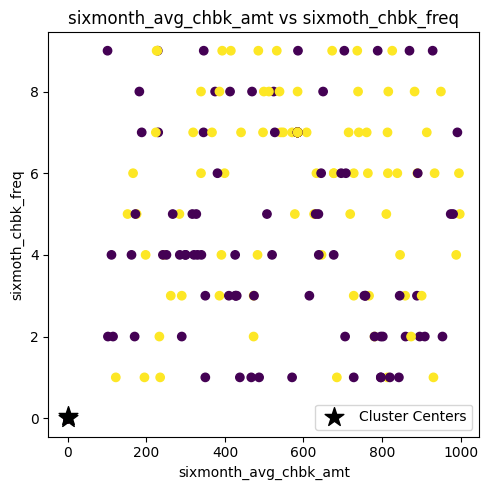

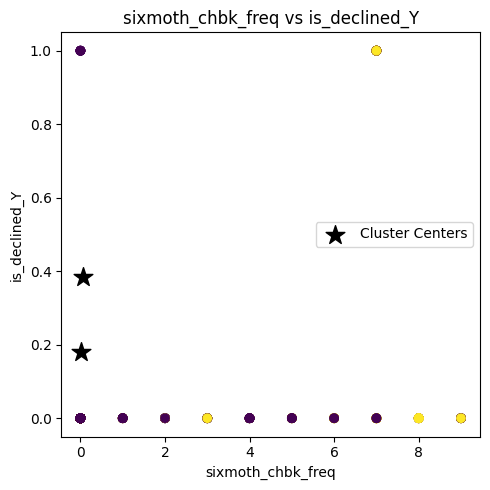

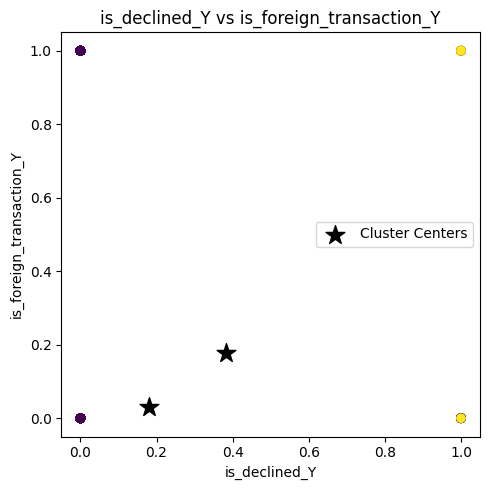

In [31]:
# Get the cluster centers
w = kmc.cluster_centers_

# Check the shapes
print("Data shape:", data.shape)
print("Cluster centers shape:", w.shape)

# Number of features used by K-Means
n_features = w.shape[1]

# Check whether the dataset has enough columns
if data.shape[1] < n_features:
    raise ValueError(
        "The data has fewer columns than the features used by K-Means."
    )

# Plot each consecutive pair of features
for i in range(n_features - 1):

    plt.figure(figsize=(5, 5))

    # Plot the data points
    plt.scatter(
        data.iloc[:, i],
        data.iloc[:, i + 1],
        c=kmc.labels_,
        cmap='viridis'
    )

    # Plot the cluster centers
    plt.scatter(
        w[:, i],
        w[:, i + 1],
        c='black',
        marker='*',
        s=200,
        label='Cluster Centers'
    )

    # Add labels and title
    plt.xlabel(data.columns[i])
    plt.ylabel(data.columns[i + 1])
    plt.title(
        f'{data.columns[i]} vs {data.columns[i + 1]}'
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
data.columns

In [ ]:
## According to the above scatterplot, average_amount_transaction_day(x) and transaction_amount(y), total_number_of_declines_day(y) and transaction_amount(x) scatterplot  data is clearly  seperated into two clusters.
## Other scatterplots data are not clearly grouped into  two clusters.

In [35]:
## Removing the features from the dataset which  data is not clustered  into two groups seperately. The reason is  because if consider all the high correlated
## features it can create the distance bias. Due to this reason,  data can be mess. So then we only consider most important features

In [36]:
data = data.drop(
    [
        'daily_chargeback_avg_amt',
        'sixmonth_avg_chbk_amt',
        'sixmoth_chbk_freq',
        'is_declined_Y',
        'is_foreign_transaction_Y',
        'is_high_risk_country_Y',
    ],
    axis=1,
    errors='ignore',
)

data.head()

,average_amount_transaction_day,transaction_amount,total_number_of_declines_day
0,100.0,3000.0,5
1,100.0,4300.0,5
2,185.5,4823.0,5
3,185.5,5008.5,8
4,500.0,26000.0,0


In [37]:
kmc=KMeans(n_clusters=2)
kmc.fit_transform(data)

array([[ 2308.18776555, 21023.95671107],
       [ 1039.13260225, 19724.64586361],
       [  523.7973716 , 19199.18755461],
       ...,
       [15520.48399141,  3213.71422131],
       [ 6800.17666947, 12036.08730839],
       [30734.65474338, 12009.13705797]])

In [38]:
kmc.labels_

array([0, 0, 0, ..., 1, 0, 1])

Data shape: (3075, 3)
Cluster centers shape: (2, 3)


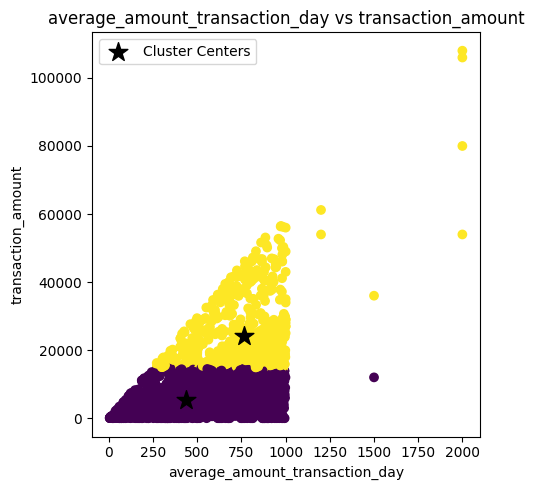

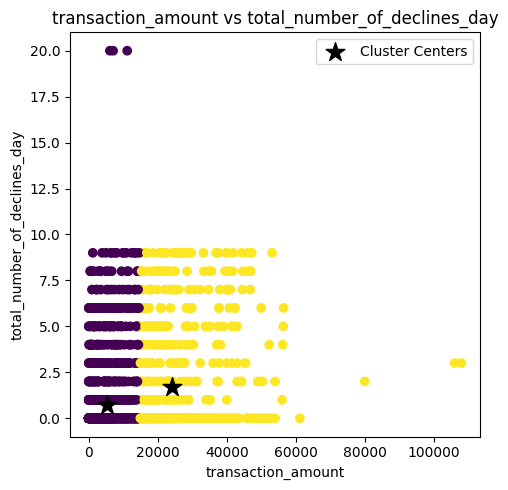

In [39]:
w = kmc.cluster_centers_

# Check the shapes
print("Data shape:", data.shape)
print("Cluster centers shape:", w.shape)

# Number of features used by K-Means
n_features = w.shape[1]

# Check whether the dataset has enough columns
if data.shape[1] < n_features:
    raise ValueError(
        "The data has fewer columns than the features used by K-Means."
    )

# Plot each consecutive pair of features
for i in range(n_features - 1):

    plt.figure(figsize=(5, 5))

    # Plot the data points
    plt.scatter(
        data.iloc[:, i],
        data.iloc[:, i + 1],
        c=kmc.labels_,
        cmap='viridis'
    )

    # Plot the cluster centers
    plt.scatter(
        w[:, i],
        w[:, i + 1],
        c='black',
        marker='*',
        s=200,
        label='Cluster Centers'
    )

    # Add labels and title
    plt.xlabel(data.columns[i])
    plt.ylabel(data.columns[i + 1])
    plt.title(
        f'{data.columns[i]} vs {data.columns[i + 1]}'
    )

    plt.legend()
    plt.tight_layout()
    plt.show()
